# Proyecto Integrador - Accidentes de tránsito en EE.UU. (2016-2023)


In [1]:
#%pip install pandas numpy -q

In [2]:
import numpy as np
import pandas as pd

print("Numpy version:", np.__version__)
print("Pandas version:", pd.__version__)

Numpy version: 2.2.6
Pandas version: 2.2.2


### 1. Carga de los datos

In [3]:
columns = ['Severity', 'Start_Time', 'End_Time', 'Start_Lat', 'Start_Lng',
           'Distance(mi)', 'City', 'State', 'Temperature(F)', 'Humidity(%)',
           'Visibility(mi)', 'Wind_Speed(mph)', 'Weather_Condition', 'Sunrise_Sunset']
# Columnas que se van a usar. El archivo pesa varios GB y tiene 46 columnas,
# por eso solo se cargan las necesarias para no llenar la memoria.

text_columns = {'City': 'category', 'State': 'category',
                'Weather_Condition': 'category', 'Sunrise_Sunset': 'category'}
# Las columnas de texto que se repiten mucho se cargan como categoría para ahorrar memoria.

df = pd.read_csv('US_Accidents_March23.csv', usecols=columns, dtype=text_columns)

print(f'Filas: {len(df):,}')
print('Columnas:', len(df.columns))
df.head()

Filas: 7,728,394
Columnas: 14


,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,Distance(mi),City,State,Temperature(F),Humidity(%),Visibility(mi),Wind_Speed(mph),Weather_Condition,Sunrise_Sunset
0,3,2016-02-08 05:46:00,2016-02-08 11:00:00,39.865147,-84.058723,0.01,Dayton,OH,36.9,91.0,10.0,NaN,Light Rain,Night
1,2,2016-02-08 06:07:59,2016-02-08 06:37:59,39.928059,-82.831184,0.01,Reynoldsburg,OH,37.9,100.0,10.0,NaN,Light Rain,Night
2,2,2016-02-08 06:49:27,2016-02-08 07:19:27,39.063148,-84.032608,0.01,Williamsburg,OH,36.0,100.0,10.0,3.5,Overcast,Night
3,3,2016-02-08 07:23:34,2016-02-08 07:53:34,39.747753,-84.205582,0.01,Dayton,OH,35.1,96.0,9.0,4.6,Mostly Cloudy,Night
4,2,2016-02-08 07:39:07,2016-02-08 08:09:07,39.627781,-84.188354,0.01,Dayton,OH,36.0,89.0,6.0,3.5,Mostly Cloudy,Day


### 2. Exploración inicial

In [4]:
print('Tipos de datos:')
print(df.dtypes)
# Muestra el tipo de datos de cada columna del DataFrame.

print()
missing = df.isna().sum()
# Cuenta los valores nulos por columna y los almacena en la variable missing.

print('Columnas con nulos:')
print(missing[missing > 0])

Tipos de datos:
Severity                int64
Start_Time             object
End_Time               object
Start_Lat             float64
Start_Lng             float64
Distance(mi)          float64
City                 category
State                category
Temperature(F)        float64
Humidity(%)           float64
Visibility(mi)        float64
Wind_Speed(mph)       float64
Weather_Condition    category
Sunrise_Sunset       category
dtype: object



Columnas con nulos:
City                    253
Temperature(F)       163853
Humidity(%)          174144
Visibility(mi)       177098
Wind_Speed(mph)      571233
Weather_Condition    173459
Sunrise_Sunset        23246
dtype: int64


In [5]:
numeric_columns = ['Severity', 'Distance(mi)', 'Temperature(F)', 'Humidity(%)',
                   'Visibility(mi)', 'Wind_Speed(mph)']
# Columnas numéricas que se van a analizar.

df[numeric_columns].describe().round(2)

,Severity,Distance(mi),Temperature(F),Humidity(%),Visibility(mi),Wind_Speed(mph)
count,7728394.00,7728394.00,7564541.00,7554250.00,7551296.00,7157161.00
mean,2.21,0.56,61.66,64.83,9.09,7.69
std,0.49,1.78,19.01,22.82,2.69,5.42
min,1.00,0.00,-89.00,1.00,0.00,0.00
25%,2.00,0.00,49.00,48.00,10.00,4.60
50%,2.00,0.03,64.00,67.00,10.00,7.00
75%,2.00,0.46,76.00,84.00,10.00,10.40
max,4.00,441.75,207.00,100.00,140.00,1087.00


### 3. Renombrar columnas

In [6]:
column_map = {
    'Severity': 'severity',
    'Start_Time': 'start_time',
    'End_Time': 'end_time',
    'Start_Lat': 'lat',
    'Start_Lng': 'lng',
    'Distance(mi)': 'distance',
    'City': 'city',
    'State': 'state',
    'Temperature(F)': 'temperature',
    'Humidity(%)': 'humidity',
    'Visibility(mi)': 'visibility',
    'Wind_Speed(mph)': 'wind_speed',
    'Weather_Condition': 'weather',
    'Sunrise_Sunset': 'day_night',
}
# Diccionario que cambia los nombres de las columnas por nombres cortos y sin unidades.

df = df[list(column_map)].rename(columns=column_map)
# Deja solo las columnas necesarias con el nombre nuevo.

print('Columnas:', list(df.columns))
df.head(3)

Columnas: ['severity', 'start_time', 'end_time', 'lat', 'lng', 'distance', 'city', 'state', 'temperature', 'humidity', 'visibility', 'wind_speed', 'weather', 'day_night']


,severity,start_time,end_time,lat,lng,distance,city,state,temperature,humidity,visibility,wind_speed,weather,day_night
0,3,2016-02-08 05:46:00,2016-02-08 11:00:00,39.865147,-84.058723,0.01,Dayton,OH,36.9,91.0,10.0,NaN,Light Rain,Night
1,2,2016-02-08 06:07:59,2016-02-08 06:37:59,39.928059,-82.831184,0.01,Reynoldsburg,OH,37.9,100.0,10.0,NaN,Light Rain,Night
2,2,2016-02-08 06:49:27,2016-02-08 07:19:27,39.063148,-84.032608,0.01,Williamsburg,OH,36.0,100.0,10.0,3.5,Overcast,Night


### 4. Conversión de fechas y duración del accidente

In [7]:
df['start_time'] = pd.to_datetime(df['start_time'], format='mixed', errors='coerce')
df['end_time'] = pd.to_datetime(df['end_time'], format='mixed', errors='coerce')
# Convierte el texto de las dos columnas en fechas reales.
# Se usa format='mixed' porque algunas fechas traen nanosegundos ("2016-02-08 05:46:00.000000000")
# y sin eso pandas las dejaría como NaT.

df['duration_min'] = (df['end_time'] - df['start_time']).dt.total_seconds() / 60
# Calcula cuánto duró el impacto del accidente en el tráfico, en minutos.

print(f'Fechas no válidas:  {int(df["start_time"].isna().sum() + df["end_time"].isna().sum())}')
print(f'Duración mediana: {np.nanmedian(df["duration_min"]):.1f} min')
print(f'Duración media:   {np.nanmean(df["duration_min"]):.1f} min')
print(f'Duración máxima:  {np.nanmax(df["duration_min"]):.1f} min')

Fechas no válidas:  0
Duración mediana: 74.8 min
Duración media:   444.4 min
Duración máxima:  2812939.0 min


### 5. Filtro de registros válidos

In [8]:
start = df['start_time']
# Columna de fecha que se usa para filtrar.

mask = (
    (start.dt.year >= 2016) & (start.dt.year <= 2023)
    & (df['severity'] >= 1) & (df['severity'] <= 4)
    & (df['duration_min'] > 1) & (df['duration_min'] < 1440)
    & (df['distance'] >= 0) & (df['distance'] < 50)
    & df['temperature'].notna() & (df['temperature'] > -40) & (df['temperature'] < 130)
    & df['humidity'].notna()
    & df['visibility'].notna()
    & df['wind_speed'].notna() & (df['wind_speed'] < 100)
    & df['weather'].notna()
    & df['day_night'].notna()
    & df['city'].notna() & df['state'].notna()
)
# Reúne todas las condiciones válidas en una sola máscara:
# años del dataset, severidad 1 a 4, duración entre 1 minuto y 1 día,
# distancia razonable, clima sin nulos y valores físicamente posibles.

print(f'Filas antes:         {len(df):,}')
print(f'Filas que se quitan: {int((~mask).sum()):,}')

df = df[mask].copy()
# Conserva solo las filas que cumplen la máscara.
print(f'Filas después:       {len(df):,}')

Filas antes:         7,728,394
Filas que se quitan: 695,513


Filas después:       7,032,881


### 6. Nuevas columnas legibles

In [9]:
df['severity_label'] = np.select(
    [df['severity'] == 1, df['severity'] == 2, df['severity'] == 3, df['severity'] == 4],
    ['Baja', 'Moderada', 'Alta', 'Grave'],
    default='Otro'
)
# Cambia los códigos de severidad por etiquetas legibles.

df['day_night'] = np.where(df['day_night'] == 'Day', 'Día', 'Noche')
# Traduce si el accidente ocurrió de día o de noche.

hour = df['start_time'].dt.hour.to_numpy()
# Extrae la hora de cada accidente como arreglo de NumPy.

df['shift'] = np.where(hour < 6, 'Madrugada',
              np.where(hour < 12, 'Mañana',
              np.where(hour < 18, 'Tarde', 'Noche')))
# Crea el turno del día a partir de la hora.

print(df['severity_label'].value_counts())
print()
print(df['day_night'].value_counts())
print()
print(df['shift'].value_counts())

severity_label
Moderada    5654502
Alta        1137712
Grave        175475
Baja          65192
Name: count, dtype: int64

day_night
Día      4915106
Noche    2117775
Name: count, dtype: int64



shift
Tarde        2704234
Mañana       2338205
Noche        1309304
Madrugada     681138
Name: count, dtype: int64


### 7. Recorte de valores extremos

In [10]:
print('Antes:')
print(f'  Distancia máxima:   {df["distance"].max():.1f} mi')
print(f'  Temperatura máxima: {df["temperature"].max():.1f} F')
print(f'  Visibilidad máxima: {df["visibility"].max():.1f} mi')
print(f'  Viento máximo:      {df["wind_speed"].max():.1f} mph')

df['distance'] = np.clip(df['distance'], 0, 20)
df['temperature'] = np.clip(df['temperature'], -20, 110)
df['visibility'] = np.clip(df['visibility'], 0, 10)
df['wind_speed'] = np.clip(df['wind_speed'], 0, 40)
# Recorta los valores extremos a un rango razonable.

print('Después:')
print(f'  Distancia máxima:   {df["distance"].max():.1f} mi')
print(f'  Temperatura máxima: {df["temperature"].max():.1f} F')
print(f'  Visibilidad máxima: {df["visibility"].max():.1f} mi')
print(f'  Viento máximo:      {df["wind_speed"].max():.1f} mph')

Antes:
  Distancia máxima:   50.0 mi
  Temperatura máxima: 129.2 F
  Visibilidad máxima: 140.0 mi
  Viento máximo:      99.0 mph
Después:
  Distancia máxima:   20.0 mi
  Temperatura máxima: 110.0 F
  Visibilidad máxima: 10.0 mi
  Viento máximo:      40.0 mph


### 8. Muestra y exportación del dataset limpio

In [11]:
df = df.sample(n=min(200000, len(df)), random_state=42).sort_values('start_time')
# Toma una muestra de 200.000 accidentes para que el análisis y la app carguen rápido.

final_columns = ['start_time', 'severity', 'severity_label', 'duration_min', 'distance',
                 'city', 'state', 'lat', 'lng', 'temperature', 'humidity',
                 'visibility', 'wind_speed', 'weather', 'day_night', 'shift']
# Orden final de las columnas del CSV.

df = df[final_columns].reset_index(drop=True)
# Deja solo esas columnas y reinicia el índice.

df.to_csv('accidentes_limpios.csv', index=False)
# Exporta el dataset limpio.

print('Guardado: accidentes_limpios.csv')
print(f'Filas: {len(df):,} | Columnas: {len(df.columns)}')

Guardado: accidentes_limpios.csv
Filas: 200,000 | Columnas: 16


### 9. Verificación del archivo exportado

In [12]:
check = pd.read_csv('accidentes_limpios.csv', parse_dates=['start_time'])
# Vuelve a leer el archivo exportado.

print(f'Filas: {len(check):,}')
print(f'Columnas: {len(check.columns)}')
print(f'Nulos en total: {int(check.isna().sum().sum())}')
print(f'Rango: {check["start_time"].min().date()} -> {check["start_time"].max().date()}')
print(f'Severidad media: {check["severity"].mean():.2f}')
print(f'Duración mediana: {check["duration_min"].median():.1f} min')
print(f'Estados: {check["state"].nunique()}')
check.head()

Filas: 200,000
Columnas: 16
Nulos en total: 0
Rango: 2016-02-08 -> 2023-03-31
Severidad media: 2.20
Duración mediana: 75.0 min
Estados: 49


,start_time,severity,severity_label,duration_min,distance,city,state,lat,lng,temperature,humidity,visibility,wind_speed,weather,day_night,shift
0,2016-02-08 07:39:07,2,Moderada,30.0,0.01,Dayton,OH,39.627781,-84.188354,36.0,89.0,6.0,3.5,Mostly Cloudy,Día,Mañana
1,2016-02-08 08:43:20,2,Moderada,30.0,0.01,Dayton,OH,39.745888,-84.170410,33.8,100.0,3.0,2.3,Overcast,Día,Mañana
2,2016-02-09 07:15:41,2,Moderada,30.0,0.01,Dayton,OH,39.746593,-84.239120,21.9,92.0,2.0,12.7,Light Snow,Noche,Mañana
3,2016-02-09 08:10:20,2,Moderada,30.0,0.00,Carroll,OH,39.834282,-82.743820,21.9,85.0,0.8,11.5,Light Snow,Día,Mañana
4,2016-02-09 08:35:53,3,Alta,30.0,0.01,Maple Heights,OH,41.424404,-81.578674,32.0,82.0,10.0,12.7,Overcast,Día,Mañana


## Avance 2: Visualización de datos
NumPy, Matplotlib, Seaborn y Plotly sobre el dataset limpio `accidentes_limpios.csv`.

In [13]:
#%pip install seaborn plotly -q

import time
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import plotly
import plotly.express as px

sns.set_theme(style='whitegrid')
print('Matplotlib version:', matplotlib.__version__)
print('Seaborn version:', sns.__version__)
print('Plotly version:', plotly.__version__)

Matplotlib version: 3.10.3
Seaborn version: 0.13.2
Plotly version: 7.1.0


In [14]:
df = pd.read_csv('accidentes_limpios.csv', parse_dates=['start_time'])
# Carga el dataset limpio que se exportó en el avance 1.

print('Filas:', len(df))
print('Columnas:', len(df.columns))
print()
print(df.dtypes)
df.head()

Filas: 200000
Columnas: 16

start_time        datetime64[ns]
severity                   int64
severity_label            object
duration_min             float64
distance                 float64
city                      object
state                     object
lat                      float64
lng                      float64
temperature              float64
humidity                 float64
visibility               float64
wind_speed               float64
weather                   object
day_night                 object
shift                     object
dtype: object


,start_time,severity,severity_label,duration_min,distance,city,state,lat,lng,temperature,humidity,visibility,wind_speed,weather,day_night,shift
0,2016-02-08 07:39:07,2,Moderada,30.0,0.01,Dayton,OH,39.627781,-84.188354,36.0,89.0,6.0,3.5,Mostly Cloudy,Día,Mañana
1,2016-02-08 08:43:20,2,Moderada,30.0,0.01,Dayton,OH,39.745888,-84.170410,33.8,100.0,3.0,2.3,Overcast,Día,Mañana
2,2016-02-09 07:15:41,2,Moderada,30.0,0.01,Dayton,OH,39.746593,-84.239120,21.9,92.0,2.0,12.7,Light Snow,Noche,Mañana
3,2016-02-09 08:10:20,2,Moderada,30.0,0.00,Carroll,OH,39.834282,-82.743820,21.9,85.0,0.8,11.5,Light Snow,Día,Mañana
4,2016-02-09 08:35:53,3,Alta,30.0,0.01,Maple Heights,OH,41.424404,-81.578674,32.0,82.0,10.0,12.7,Overcast,Día,Mañana


### Ejercicio 1 - Métricas con arrays de NumPy

In [15]:
duracion = df['duration_min'].to_numpy()
temperatura = df['temperature'].to_numpy()
# Pasa las dos columnas numéricas a arrays de NumPy.

print(type(duracion), duracion.dtype, duracion.shape)
print(type(temperatura), temperatura.dtype, temperatura.shape)

<class 'numpy.ndarray'> float64 (200000,)
<class 'numpy.ndarray'> float64 (200000,)


In [16]:
def metricas(arr):
    return {'suma': np.sum(arr), 'media': np.mean(arr), 'mediana': np.median(arr),
            'maximo': np.max(arr), 'minimo': np.min(arr), 'desv_std': np.std(arr)}
# Calcula las métricas básicas de un array.

tabla = pd.DataFrame({'duration_min': metricas(duracion), 'temperature': metricas(temperatura)})
tabla.round(2)

,duration_min,temperature
suma,21792770.23,12371791.40
media,108.96,61.86
mediana,75.02,64.00
maximo,1439.98,110.00
minimo,4.52,-20.00
desv_std,124.38,18.99


In [17]:
for nombre, arr in [('duration_min', duracion), ('temperature', temperatura)]:
    p = np.percentile(arr, [25, 50, 75, 90, 99])
    print(nombre, '-> p25, p50, p75, p90, p99:', np.round(p, 2))
# Percentiles para entender la distancia entre media y mediana.

duration_min -> p25, p50, p75, p90, p99: [ 34.07  75.02 125.2  240.   693.5 ]
temperature -> p25, p50, p75, p90, p99: [49.  64.  76.  84.9 96. ]


In [18]:
mascara_dur = duracion > duracion.mean()
mascara_temp = temperatura > temperatura.mean()
# Máscaras booleanas: accidentes por encima de la media.

print('Duración > media (%.2f min): %d accidentes (%.1f%%)' % (duracion.mean(), mascara_dur.sum(), 100 * mascara_dur.mean()))
print('Temperatura > media (%.2f F): %d accidentes (%.1f%%)' % (temperatura.mean(), mascara_temp.sum(), 100 * mascara_temp.mean()))
print('Las dos condiciones a la vez:', (mascara_dur & mascara_temp).sum())

Duración > media (108.96 min): 61443 accidentes (30.7%)
Temperatura > media (61.86 F): 109586 accidentes (54.8%)
Las dos condiciones a la vez: 32646


In [19]:
t0 = time.perf_counter()
total_for = 0.0
for i in range(len(duracion)):
    total_for += duracion[i]
t_for = time.perf_counter() - t0
# Suma de las duraciones con un ciclo for.

t0 = time.perf_counter()
total_vec = np.sum(duracion)
t_vec = time.perf_counter() - t0
# La misma suma vectorizada con NumPy.

print('Ciclo for:     %.4f s -> total %.2f' % (t_for, total_for))
print('Vectorizado:   %.4f s -> total %.2f' % (t_vec, total_vec))
print('El vectorizado es %.0f veces más rápido' % (t_for / t_vec))

Ciclo for:     0.0189 s -> total 21792770.23
Vectorizado:   0.0001 s -> total 21792770.23
El vectorizado es 217 veces más rápido


### Análisis y hallazgos - Ejercicio 1

**Columnas elegidas.** `duration_min` (cuánto duró el impacto del accidente en el tráfico) y `temperature` (el clima al momento del accidente),
porque son las dos variables numéricas continuas más importantes para el análisis: una mide la consecuencia y la otra el contexto.

**Media vs mediana.** En `duration_min` la media es 108,96 min y la mediana 75,02 min: la distribución está **sesgada a la derecha**,
la mayoría de los accidentes se resuelve en poco más de una hora y unos pocos que duran casi un día (máximo 1.439,98 min) inflan la media.
La máscara lo confirma: solo el **30,7%** de los accidentes supera la media de duración. En `temperature` pasa lo contrario: media 61,86 F
y mediana 64 F, con un leve sesgo a la izquierda por los accidentes en días muy fríos; el **54,8%** está por encima de la media.

**For vs vectorizado.** Los dos dan 21.792.770,23, pero el `for` tardó 0,0189 s y `np.sum(duracion)` 0,0001 s, unas **217 veces** más rápido.
El `for` lo ejecuta Python elemento por elemento, revisando tipos en cada vuelta; la versión vectorizada la resuelve NumPy en un solo ciclo en C
sobre memoria contigua y con tipo fijo. *(Los tiempos cambian un poco en cada ejecución.)*

### Ejercicio 2 - Gráficos estáticos (Matplotlib y Seaborn)

Accidentes con duración >= 300 min: 16039 de 200000


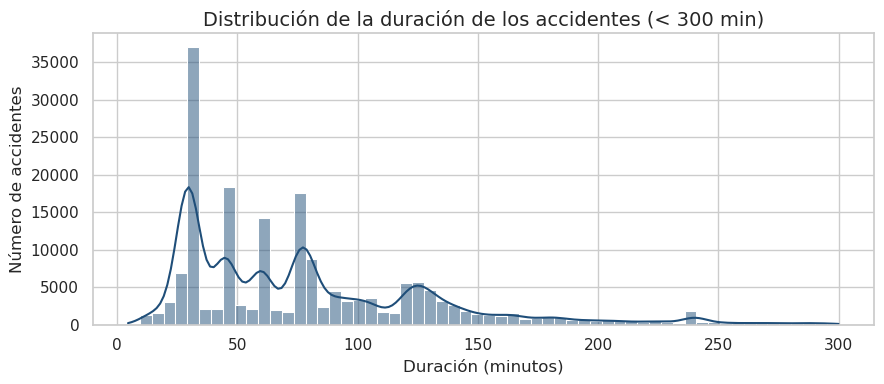

In [20]:
print('Accidentes con duración >= 300 min:', (df['duration_min'] >= 300).sum(), 'de', len(df))
# Se recorta a menos de 300 minutos porque los atípicos aplastan la forma.

plt.figure(figsize=(9, 4))
sns.histplot(df['duration_min'][df['duration_min'] < 300], bins=60, kde=True, color='#1F4E79')
plt.title('Distribución de la duración de los accidentes (< 300 min)', fontsize=14)
plt.xlabel('Duración (minutos)', fontsize=12)
plt.ylabel('Número de accidentes', fontsize=12)
plt.tight_layout()
plt.show()

state
CA    22.32
FL    11.78
TX     7.54
SC     4.93
NY     4.68
NC     4.34
PA     3.85
VA     3.81
MN     2.58
OR     2.32
Name: % del total, dtype: float64


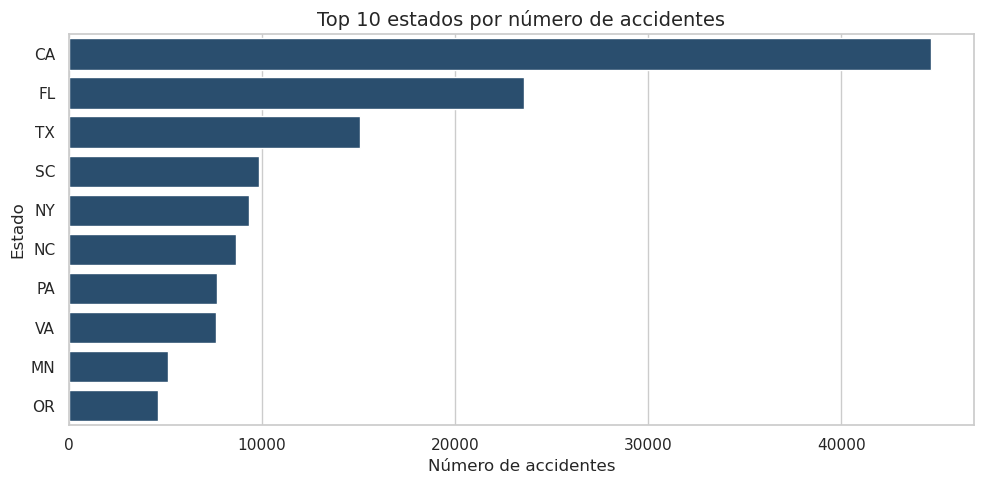

In [21]:
top10 = df['state'].value_counts().head(10)
# Los 10 estados con más accidentes.
print((top10 / len(df) * 100).round(2).rename('% del total'))

plt.figure(figsize=(10, 5))
sns.barplot(x=top10.values, y=top10.index, color='#1F4E79')
plt.title('Top 10 estados por número de accidentes', fontsize=14)
plt.xlabel('Número de accidentes', fontsize=12)
plt.ylabel('Estado', fontsize=12)
plt.tight_layout()
plt.show()

start_time
2016     9410
2017    16365
2018    20367
2019    25047
2020    32033
2021    42349
2022    47722
2023     6707
Name: count, dtype: int64


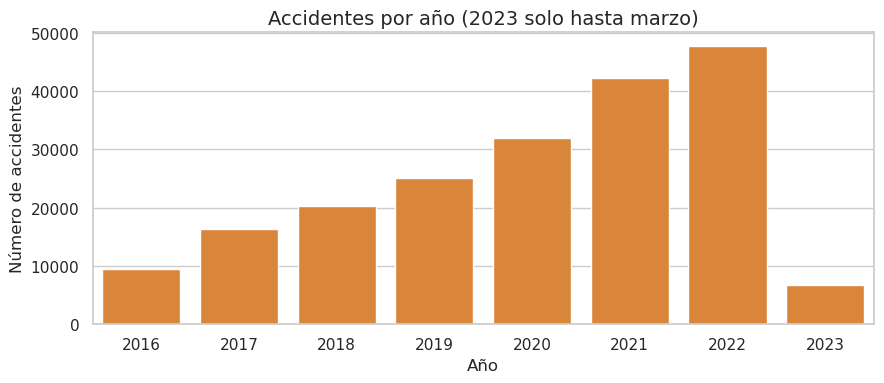

In [22]:
por_anio = df['start_time'].dt.year.value_counts().sort_index()
# Número de accidentes por año (2023 solo llega hasta marzo).
print(por_anio)

plt.figure(figsize=(9, 4))
sns.barplot(x=por_anio.index, y=por_anio.values, color='#F5851F')
plt.title('Accidentes por año (2023 solo hasta marzo)', fontsize=14)
plt.xlabel('Año', fontsize=12)
plt.ylabel('Número de accidentes', fontsize=12)
plt.tight_layout()
plt.show()

                   count    25%     50%     75%      max
severity_label                                          
Baja              1843.0  29.68   44.78   59.77   484.00
Moderada        161110.0  44.62   77.92  129.10  1439.98
Alta             31992.0  29.62   44.47   60.67  1304.93
Grave             5055.0  60.00  125.63  360.00  1439.00


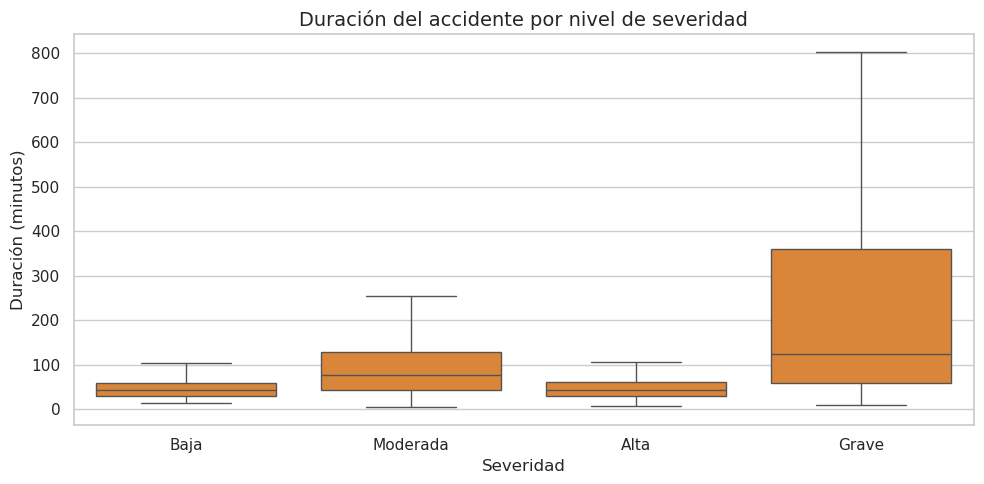

In [23]:
orden = ['Baja', 'Moderada', 'Alta', 'Grave']
# Orden lógico de la severidad.
print(df.groupby('severity_label')['duration_min'].describe().loc[orden, ['count', '25%', '50%', '75%', 'max']].round(2))

plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='severity_label', y='duration_min', order=orden, showfliers=False, color='#F5851F')
plt.title('Duración del accidente por nivel de severidad', fontsize=14)
plt.xlabel('Severidad', fontsize=12)
plt.ylabel('Duración (minutos)', fontsize=12)
plt.tight_layout()
plt.show()

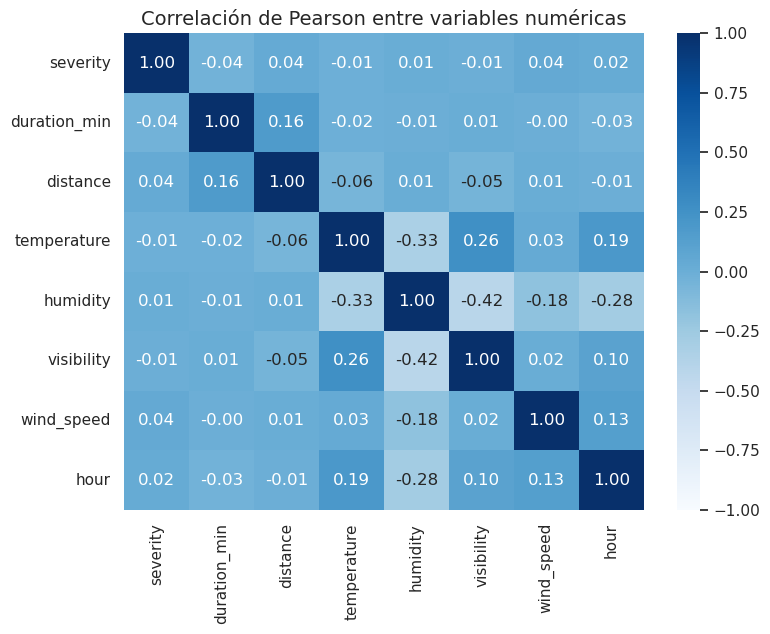

In [24]:
df['hour'] = df['start_time'].dt.hour
# Se agrega la hora como variable numérica.
num = ['severity', 'duration_min', 'distance', 'temperature', 'humidity',
       'visibility', 'wind_speed', 'hour']

corr = df[num].corr()
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', vmin=-1, vmax=1)
plt.title('Correlación de Pearson entre variables numéricas', fontsize=14)
plt.tight_layout()
plt.show()

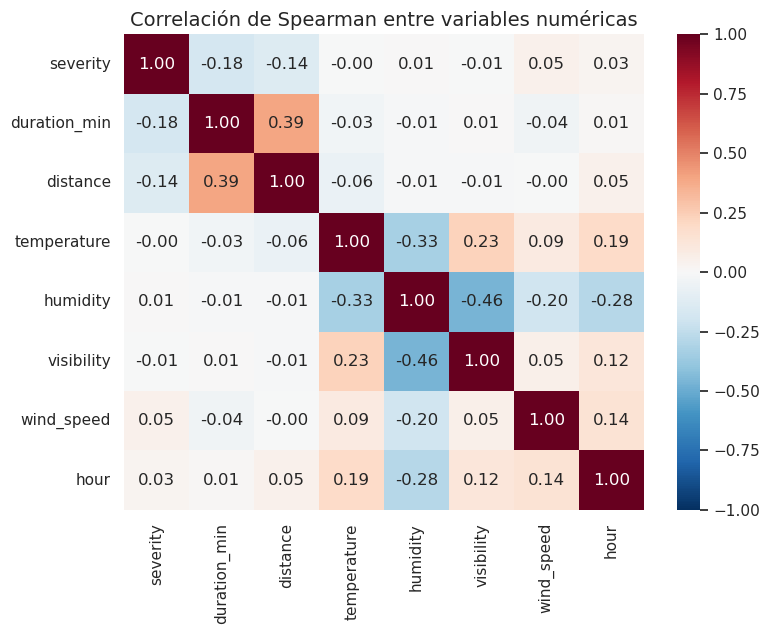

In [25]:
corr_s = df[num].corr(method='spearman')
# Pearson es sensible a los atípicos, así que se compara con Spearman (por rangos).
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr_s, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1)
plt.title('Correlación de Spearman entre variables numéricas', fontsize=14)
plt.tight_layout()
plt.show()

### Análisis y hallazgos - Ejercicio 2

**Histograma.** Recortado a `duration_min < 300` (quedan por fuera 16.039 accidentes, el 8%). Es una distribución **sesgada a la derecha**
con atípicos y con picos en valores redondos: 30, 45, 60 y 75 minutos. Solo en 30,0 min hay 27.165 accidentes, lo que parece una duración
por defecto que asigna la fuente cuando no se conoce la hora real de fin.

**Barras.** **California** se destaca con el **22,32%** de los accidentes de la muestra, seguida de Florida (11,78%) y Texas (7,54%):
entre los tres suman más del 41%. Son los estados más poblados y con más tráfico, y además los que más reportes tienen en las fuentes del dataset.
Por año, los registros crecen de 9.410 en 2016 a 47.722 en 2022; 2023 se ve bajo porque los datos llegan solo hasta marzo.

**Boxplot.** Sin atípicos, la severidad **Grave** tiene mediana de 125,6 min y tercer cuartil de 360 min, muy por encima del resto.
Llama la atención que **Alta** (mediana 44,5 min) dure menos que **Moderada** (77,9 min): la severidad mide el impacto en el tráfico, no la duración.

**Correlación.** En Pearson el par más correlacionado es `humidity`-`visibility` (**-0,42**): con más humedad (lluvia, niebla) baja la visibilidad.
Con Spearman aparece una relación que Pearson tapaba por los atípicos: `duration_min`-`distance` = **0,39**, los accidentes que afectan más
tramo de vía duran más. La severidad casi no se correlaciona con el clima (todas cerca de 0). Ninguna de estas relaciones prueba **causalidad**:
son asociaciones, y por ejemplo la humedad y la visibilidad dependen las dos del tipo de clima.

### Ejercicio 3 - Gráficos interactivos (Plotly)

In [26]:
top = (df.groupby('state')
         .agg(Accidentes=('severity', 'size'), Severidad_media=('severity', 'mean'),
              Duracion_mediana=('duration_min', 'median'))
         .sort_values('Accidentes', ascending=False).head(15).reset_index())
top['Severidad_media'] = top['Severidad_media'].round(2)
top['Duracion_mediana'] = top['Duracion_mediana'].round(1)
# Resumen por estado: número de accidentes, severidad media y duración mediana.

fig_bar = px.bar(top, x='Accidentes', y='state', orientation='h',
                 hover_data=['Severidad_media', 'Duracion_mediana'], color_discrete_sequence=['#1F4E79'],
                 title='Top 15 estados por número de accidentes',
                 labels={'Accidentes': 'Número de accidentes', 'state': 'Estado'})
fig_bar.update_layout(yaxis={'categoryorder': 'total ascending'})
fig_bar.show()

In [27]:
muestra = df.sample(3000, random_state=42).copy()
# Muestra de 3000 accidentes (graficar 200 mil puntos no tiene sentido).

fig_sc = px.scatter(muestra, x='lng', y='lat', color='severity_label', opacity=0.6,
                    category_orders={'severity_label': ['Baja', 'Moderada', 'Alta', 'Grave']},
                    color_discrete_map={'Baja': '#7FB3D5', 'Moderada': '#1F4E79',
                                        'Alta': '#F5851F', 'Grave': '#C0392B'},
                    hover_data=['city', 'state', 'start_time', 'weather', 'duration_min'],
                    title='Ubicación de los accidentes (muestra de 3000, longitud vs latitud)',
                    labels={'lng': 'Longitud', 'lat': 'Latitud', 'severity_label': 'Severidad'})
fig_sc.show()
print(muestra['severity_label'].value_counts())

severity_label
Moderada    2413
Alta         495
Grave         64
Baja          28
Name: count, dtype: int64


In [28]:
fig_bar.write_html('barras_estados.html', include_plotlyjs='cdn')
fig_sc.write_html('scatter_ubicacion.html', include_plotlyjs='cdn')
# Exporta los dos gráficos a HTML para abrirlos en el navegador o usarlos en el dashboard.
print('Guardados: barras_estados.html y scatter_ubicacion.html')

Guardados: barras_estados.html y scatter_ubicacion.html


### Análisis y hallazgos - Ejercicio 3

**Barras interactivas.** Muestran los 15 estados con más accidentes y, al pasar el mouse, la severidad media y la duración mediana de cada uno.
Así se ve, por ejemplo, que Oregon tiene una duración mediana de 130,8 min (la más alta del top) y Georgia la severidad media más alta (2,51).

**Dispersión.** Con una muestra de 3.000 accidentes (`random_state=42`) y longitud contra latitud, los puntos dibujan el mapa de EE.UU.:
se ven las costas y las grandes ciudades donde se concentran los accidentes. La muestra conserva la proporción de severidades del dataset
(2.413 Moderada, 495 Alta, 64 Grave y 28 Baja, frente a 80,6%, 16%, 2,5% y 0,9% en los 200.000).

**Ventajas frente al estático.** El detalle al pasar el mouse (ciudad, fecha, clima, duración), el zoom sobre una región y el filtro por severidad
con la leyenda sin rehacer el gráfico, y que el HTML lo abre cualquiera sin Python. En el dashboard (`app.py`) las barras por estado son el panel
principal y el mapa de puntos permite ver dónde ocurren los accidentes según los filtros de fecha, severidad y turno.